# 02 · Representation stabilization with linear CKA (all layers)

For each of the 113 checkpoints produced by `01_train_resnet18_cifar10.ipynb`, this notebook computes the **linear Centered Kernel Alignment (CKA)** between the representation of a layer at that epoch and the representation of the same layer in the final model (epoch 350).

- **Layers:** `conv1`, `layer1`, `layer2`, `layer3`, `layer4` (the five stages analysed in the thesis) and `avgpool` (the 512-d penultimate features used for the Neural Collapse analysis).
- **Data:** a fixed random subset of 1,000 CIFAR-10 *test* images (no augmentation, identical for every checkpoint).
- **Feature definition (`POOL_SPATIAL`):** by default, convolutional feature maps of shape `(N, C, H, W)` are **globally average-pooled over the spatial dimensions** to `(N, C)` before computing CKA, as in the thesis. This means `layer4` and `avgpool` are the *same* representation (avgpool is the spatial mean of layer4). Set `POOL_SPATIAL = False` to use the full flattened feature maps instead (a stricter, more expensive variant; written to separate `*_unpooled` files).
- **Stabilization epoch:** reported with two criteria (see the section below): the *first crossing* of a threshold and the *strict* version, where CKA must stay above the threshold until the end of training.

**Input:** `checkpoints/epoch_{N}.pth` from notebook 01  
**Outputs:** `cka_layerwise.csv`, `cka_stabilization_summary.csv`, `CKA_results.csv` (avgpool only; input of notebook 04), and two figures

Linear CKA (Kornblith et al., 2019) for column-centered feature matrices $X, Y$:

$$\mathrm{CKA}(X,Y)=\frac{\lVert X^\top Y\rVert_F^2}{\lVert X^\top X\rVert_F\,\lVert Y^\top Y\rVert_F}=\frac{\operatorname{tr}(K L)}{\sqrt{\operatorname{tr}(K K)\operatorname{tr}(L L)}},\quad K=XX^\top,\ L=YY^\top$$

In [1]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms

## Configuration

In [3]:
ON_KAGGLE = os.path.exists("/kaggle/working")

# Folder containing epoch_{N}.pth files produced by notebook 01.
# On Kaggle, point this at the dataset / notebook output that holds the checkpoints, e.g.
#   CHECKPOINT_DIR = Path("/kaggle/input/<your-dataset>/checkpoints")
BASE = Path(
    "/kaggle/input/notebooks/parinazghasemi/train-more-epochs"
)

CHECKPOINT_DIR = BASE / "checkpoints"

FINAL_MODEL = BASE / "final_model.pth"

HISTORY = BASE / "training_history.csv"
OUTPUT_DIR = Path("/kaggle/working" if ON_KAGGLE else ".")

SEED = 42
N_CKA = 1000                    # size of the fixed test subset
FINAL_EPOCH = 350               # reference model
LAYERS = ["conv1", "layer1", "layer2", "layer3", "layer4", "avgpool"]
THRESHOLDS = (0.95, 0.99)

# True  -> global-average-pool feature maps over H, W (thesis setting)
# False -> use full flattened feature maps (much larger, uses the GPU for the CKA computation)
POOL_SPATIAL = True
SUFFIX = "" if POOL_SPATIAL else "_unpooled"

RESULTS_FILE = OUTPUT_DIR / f"cka_layerwise{SUFFIX}.csv"
SUMMARY_FILE = OUTPUT_DIR / f"cka_stabilization_summary{SUFFIX}.csv"

# The 113 checkpointed epochs (must match notebook 01)
EPOCHS = sorted(set(
    list(range(1, 21))
    + list(range(25, 101, 5))
    + list(range(110, 221, 10))
    + list(range(220, 351, 2))
))

missing = [e for e in EPOCHS if not (CHECKPOINT_DIR / f"epoch_{e}.pth").exists()]
assert not missing, f"{len(missing)} checkpoints not found in {CHECKPOINT_DIR}, e.g. {missing[:5]}"
print(f"Found all {len(EPOCHS)} checkpoints.")

Found all 113 checkpoints.


In [4]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


## Fixed CKA subset (1,000 test images)

In [5]:
transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

test_dataset = datasets.CIFAR10(root=DATA_DIR, train=False, download=True, transform=transform_test)

# The seed is set immediately before sampling so the subset is identical on every run.
torch.manual_seed(42)
cka_indices = torch.randperm(len(test_dataset))[:N_CKA]
loader = DataLoader(Subset(test_dataset, cka_indices), batch_size=128, shuffle=False)

print("CKA samples:", len(cka_indices), "| batches:", len(loader))

100%|██████████| 170M/170M [23:05<00:00, 123kB/s]  


CKA samples: 1000 | batches: 8


## Model, feature extraction and CKA

In [6]:
model = models.resnet18(num_classes=10)
model.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
model.maxpool = nn.Identity()
model = model.to(device)

# Forward hooks store the raw output of every analysed layer.
# Note: the output of `conv1` is taken before BatchNorm/ReLU; layer1-4 outputs are after their last ReLU.
FEATURES = {}

def make_hook(name):
    def hook(module, inp, out):
        FEATURES[name] = out.detach()
    return hook

for name in LAYERS:
    getattr(model, name).register_forward_hook(make_hook(name))


def load_checkpoint(epoch):
    ckpt = torch.load(CHECKPOINT_DIR / f"epoch_{epoch}.pth", map_location=device)
    model.load_state_dict(ckpt["model_state_dict"])
    model.eval()


@torch.no_grad()
def extract_all_layers(data_loader):
    """One forward pass; returns {layer: (N, D) CPU tensor}."""
    model.eval()
    buffers = {name: [] for name in LAYERS}
    for x, _ in data_loader:
        model(x.to(device))
        for name in LAYERS:
            f = FEATURES[name]
            f = f.mean(dim=(2, 3)) if (POOL_SPATIAL and f.dim() == 4) else f.flatten(start_dim=1)
            buffers[name].append(f.cpu())
    return {name: torch.cat(parts, dim=0) for name, parts in buffers.items()}


@torch.no_grad()
def linear_CKA(X, Y):
    """Linear CKA between two (N, D) feature matrices whose rows are the same N samples."""
    dev = device if not POOL_SPATIAL else torch.device("cpu")   # unpooled features are large
    X = X.float().to(dev)
    Y = Y.float().to(dev)
    X = X - X.mean(dim=0, keepdim=True)
    Y = Y - Y.mean(dim=0, keepdim=True)

    if X.shape[1] > X.shape[0]:
        # D > N: work with the N x N Gram matrices (mathematically identical, much cheaper)
        K, L = X @ X.T, Y @ Y.T
        numerator = (K * L).sum()
        denominator = torch.sqrt(K.pow(2).sum()) * torch.sqrt(L.pow(2).sum())
    else:
        numerator = (X.T @ Y).pow(2).sum()
        denominator = torch.sqrt((X.T @ X).pow(2).sum()) * torch.sqrt((Y.T @ Y).pow(2).sum())
    return (numerator / (denominator + 1e-12)).item()

## Reference representations (epoch 350)

In [7]:
load_checkpoint(FINAL_EPOCH)
reference = extract_all_layers(loader)

for name in LAYERS:
    print(f"{name:8s} reference shape: {tuple(reference[name].shape)}")

# Sanity checks: the subset is deterministic, and CKA of a representation with itself is 1
assert torch.equal(next(iter(loader))[0], next(iter(loader))[0])
print("CKA(layer4, layer4) =", linear_CKA(reference["layer4"], reference["layer4"]))

conv1    reference shape: (1000, 64)
layer1   reference shape: (1000, 64)
layer2   reference shape: (1000, 128)
layer3   reference shape: (1000, 256)
layer4   reference shape: (1000, 512)
avgpool  reference shape: (1000, 512)
CKA(layer4, layer4) = 1.0


## Compute CKA for every checkpoint and layer
One forward pass per checkpoint serves all layers. Results are written after every epoch, so an interrupted run resumes where it stopped.

In [8]:
if RESULTS_FILE.exists():
    results = pd.read_csv(RESULTS_FILE)
    print(f"Resuming: {len(results)} epochs already done.")
else:
    results = pd.DataFrame(columns=["epoch"] + LAYERS)

rows = {int(r["epoch"]): [r[name] for name in LAYERS] for _, r in results.iterrows()}

for epoch in tqdm([e for e in EPOCHS if e not in rows]):
    load_checkpoint(epoch)
    feats = extract_all_layers(loader)
    rows[epoch] = [linear_CKA(feats[name], reference[name]) for name in LAYERS]
    del feats

    pd.DataFrame(
        [[e] + v for e, v in sorted(rows.items())], columns=["epoch"] + LAYERS
    ).to_csv(RESULTS_FILE, index=False)

  0%|          | 0/113 [00:00<?, ?it/s]

## Results

In [9]:
cka = pd.read_csv(RESULTS_FILE).sort_values("epoch").reset_index(drop=True)
epochs_cka = cka["epoch"].to_numpy()
print("Rows:", len(cka), "| missing epochs:", sorted(set(EPOCHS) - set(epochs_cka)))

# In the pooled setting, avgpool is exactly the spatial mean of layer4 -> identical curves
if POOL_SPATIAL:
    print("max |CKA(layer4) - CKA(avgpool)| =", float(np.abs(cka["layer4"] - cka["avgpool"]).max()))

    # avgpool curve: input of notebook 04 (comparison with Neural Collapse)
    cka[["epoch", "avgpool"]].rename(columns={"avgpool": "CKA"}).to_csv(OUTPUT_DIR / "CKA_results.csv", index=False)

cka.head()

Rows: 113 | missing epochs: []
max |CKA(layer4) - CKA(avgpool)| = 0.0


,epoch,conv1,layer1,layer2,layer3,layer4,avgpool
0,1,0.812076,0.541027,0.337747,0.171707,0.305183,0.305183
1,2,0.826868,0.617079,0.357641,0.286276,0.434797,0.434797
2,3,0.848204,0.704955,0.555273,0.302625,0.499333,0.499333
3,4,0.885615,0.857856,0.657041,0.395055,0.559176,0.559176
4,5,0.916097,0.902172,0.756154,0.463788,0.580107,0.580107


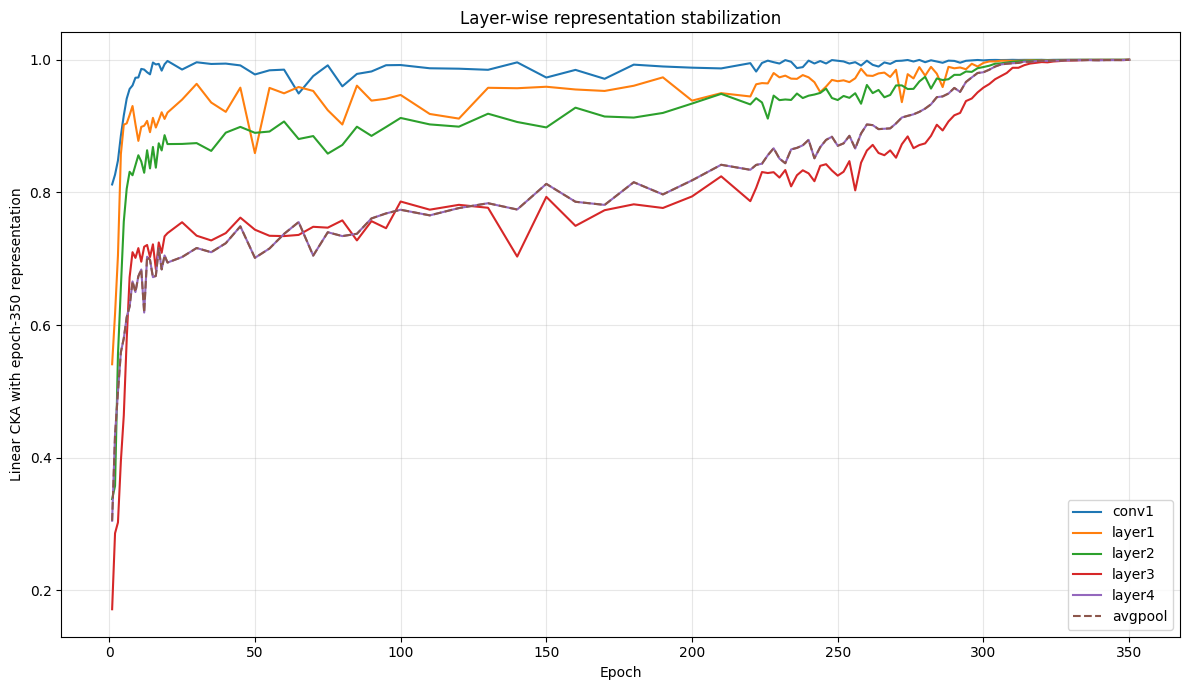

In [10]:
plt.figure(figsize=(12, 7))
for name in LAYERS:
    plt.plot(epochs_cka, cka[name], label=name, linestyle="--" if name == "avgpool" else "-")
plt.xlabel("Epoch")
plt.ylabel("Linear CKA with epoch-350 representation")
plt.title("Layer-wise representation stabilization")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / f"cka_layerwise_curves{SUFFIX}.png", dpi=200)
plt.show()

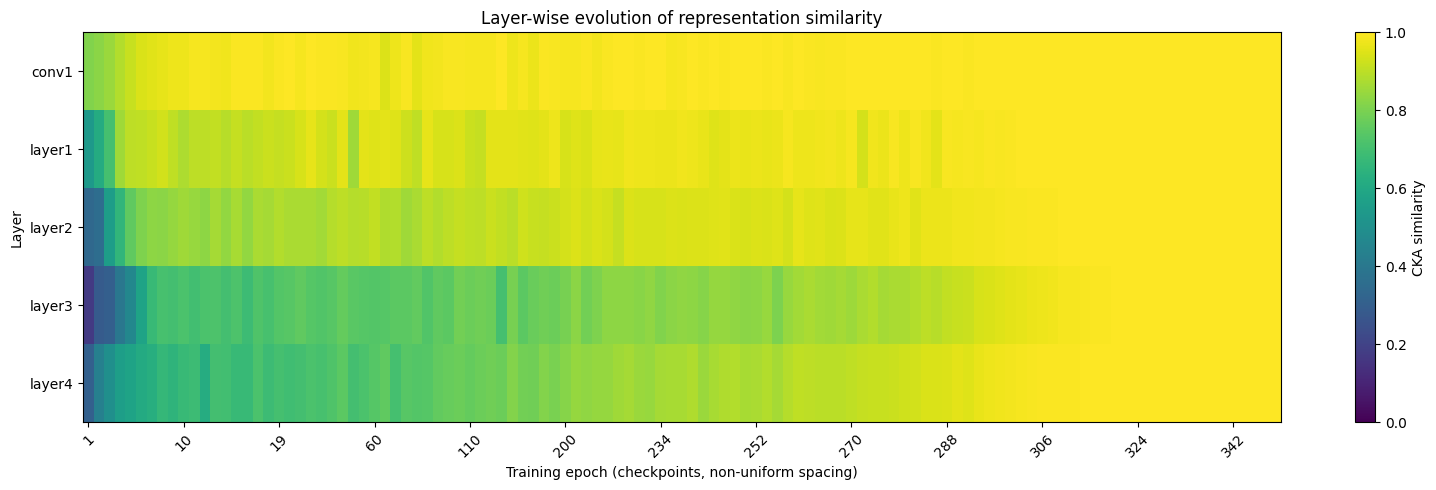

In [11]:
plot_layers = [n for n in LAYERS if n != "avgpool"]
heat = cka[plot_layers].to_numpy().T

fig, ax = plt.subplots(figsize=(16, 5))
im = ax.imshow(heat, aspect="auto", cmap="viridis", vmin=0, vmax=1)
step = max(1, len(epochs_cka) // 12)
pos = list(range(0, len(epochs_cka), step))
ax.set_xticks(pos)
ax.set_xticklabels([epochs_cka[p] for p in pos], rotation=45)
ax.set_yticks(range(len(plot_layers)))
ax.set_yticklabels(plot_layers)
ax.set_xlabel("Training epoch (checkpoints, non-uniform spacing)")
ax.set_ylabel("Layer")
ax.set_title("Layer-wise evolution of representation similarity")
fig.colorbar(im, label="CKA similarity")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / f"cka_layerwise_heatmap{SUFFIX}.png", dpi=300, bbox_inches="tight")
plt.show()

## Stabilization epochs

Two definitions are computed for each layer and threshold:

- **first crossing** – the first checkpoint with CKA ≥ threshold (CKA may fall below it again later);
- **strict** – the first checkpoint from which CKA stays ≥ threshold for *all* later checkpoints. This is the "hard stabilization" criterion defined in Section 3.6 of the thesis, and the one used for the comparison with Neural Collapse.

The two coincide only when the curve never dips back below the threshold, so report the strict version when making claims about when a representation has stabilized.

In [12]:
def first_crossing(epochs, values, threshold):
    for e, v in zip(epochs, values):
        if v >= threshold:
            return int(e)
    return None


def strict_stabilization(epochs, values, threshold):
    values = np.asarray(values)
    for i in range(len(values)):
        if np.all(values[i:] >= threshold):
            return int(epochs[i])
    return None


summary = pd.DataFrame(
    [
        {
            "layer": name,
            "threshold": t,
            "first_crossing_epoch": first_crossing(epochs_cka, cka[name], t),
            "strict_epoch": strict_stabilization(epochs_cka, cka[name], t),
        }
        for t in THRESHOLDS
        for name in LAYERS
    ]
)
summary.to_csv(SUMMARY_FILE, index=False)
summary

,layer,threshold,first_crossing_epoch,strict_epoch
0,conv1,0.95,7,70
1,layer1,0.95,30,274
2,layer2,0.95,244,270
3,layer3,0.95,298,298
4,layer4,0.95,290,290
5,avgpool,0.95,290,290
6,conv1,0.99,15,266
7,layer1,0.99,296,300
8,layer2,0.99,302,302
9,layer3,0.99,314,314


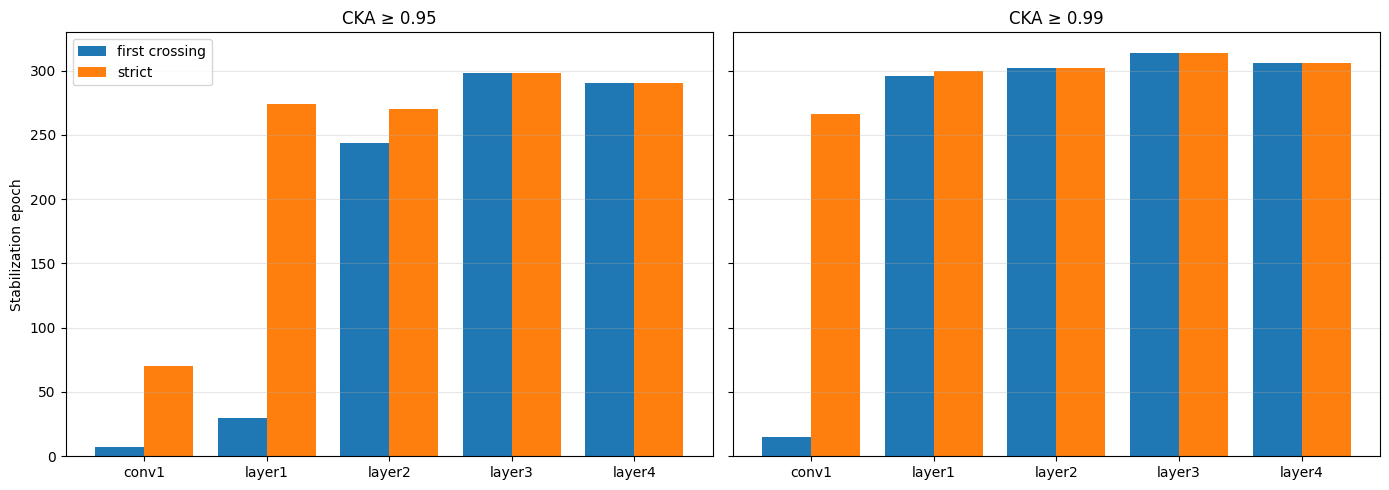

In [13]:
fig, axes = plt.subplots(1, len(THRESHOLDS), figsize=(14, 5), sharey=True)
for ax, t in zip(axes, THRESHOLDS):
    sub = summary[(summary["threshold"] == t) & (summary["layer"] != "avgpool")]
    x = np.arange(len(sub))
    ax.bar(x - 0.2, sub["first_crossing_epoch"], width=0.4, label="first crossing")
    ax.bar(x + 0.2, sub["strict_epoch"], width=0.4, label="strict")
    ax.set_xticks(x)
    ax.set_xticklabels(sub["layer"])
    ax.set_title(f"CKA ≥ {t}")
    ax.grid(True, axis="y", alpha=0.3)
axes[0].set_ylabel("Stabilization epoch")
axes[0].legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / f"cka_stabilization_by_layer{SUFFIX}.png", dpi=200)
plt.show()